# Credit Card Veri Seti İşleme

Bu notebook, Kaggle Credit Card Fraud Detection veri setini işleyerek model eğitimine hazırlar.

## Adımlar:
1. Veri yükleme ve keşif
2. Eksik değer kontrolü
3. Sınıf dağılımı analizi
4. PCA dönüşümü
5. İşlenmiş veriyi kaydetme

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Veri setini yükle
df = pd.read_csv('../data/creditcard.csv')

# İlk 5 satırı göster
print("İlk 5 Satır:")
print(df.head())

İlk 5 Satır:
   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26       V

In [3]:
# Veri setine genel bakış
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [4]:
# Sütun isimlerini yazdır
print("Sütun İsimleri:")
print(df.columns.tolist())

Sütun İsimleri:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']


In [5]:
# Veri seti boyutu
print(f"Veri Seti Boyutu: {df.shape}")

# Sütun bilgileri
print("\nVeri Seti Bilgisi:")
print(df.info())

Veri Seti Boyutu: (284807, 31)

Veri Seti Bilgisi:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 2

In [6]:
# Tanımlayıcı istatistikler
print("\nTanımlayıcı İstatistikler:")
print(df.describe())


Tanımlayıcı İstatistikler:
                Time            V1            V2            V3            V4  \
count  284807.000000  2.848070e+05  2.848070e+05  2.848070e+05  2.848070e+05   
mean    94813.859575  1.168375e-15  3.416908e-16 -1.379537e-15  2.074095e-15   
std     47488.145955  1.958696e+00  1.651309e+00  1.516255e+00  1.415869e+00   
min         0.000000 -5.640751e+01 -7.271573e+01 -4.832559e+01 -5.683171e+00   
25%     54201.500000 -9.203734e-01 -5.985499e-01 -8.903648e-01 -8.486401e-01   
50%     84692.000000  1.810880e-02  6.548556e-02  1.798463e-01 -1.984653e-02   
75%    139320.500000  1.315642e+00  8.037239e-01  1.027196e+00  7.433413e-01   
max    172792.000000  2.454930e+00  2.205773e+01  9.382558e+00  1.687534e+01   

                 V5            V6            V7            V8            V9  \
count  2.848070e+05  2.848070e+05  2.848070e+05  2.848070e+05  2.848070e+05   
mean   9.604066e-16  1.487313e-15 -5.556467e-16  1.213481e-16 -2.406331e-15   
std    1.38024

In [7]:
# Eksik değer kontrolü
print("\nEksik Değerler:")
print(df.isnull().sum())


Eksik Değerler:
Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64


## Sınıf Dağılımı ve Görselleştirme


Sınıf Dağılımı:
Class
0    284315
1       492
Name: count, dtype: int64

Sınıf Dağılımı (Yüzdelik):
Class
0    0.998273
1    0.001727
Name: proportion, dtype: float64


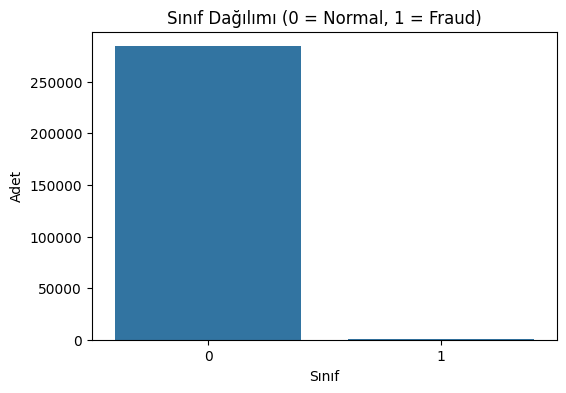

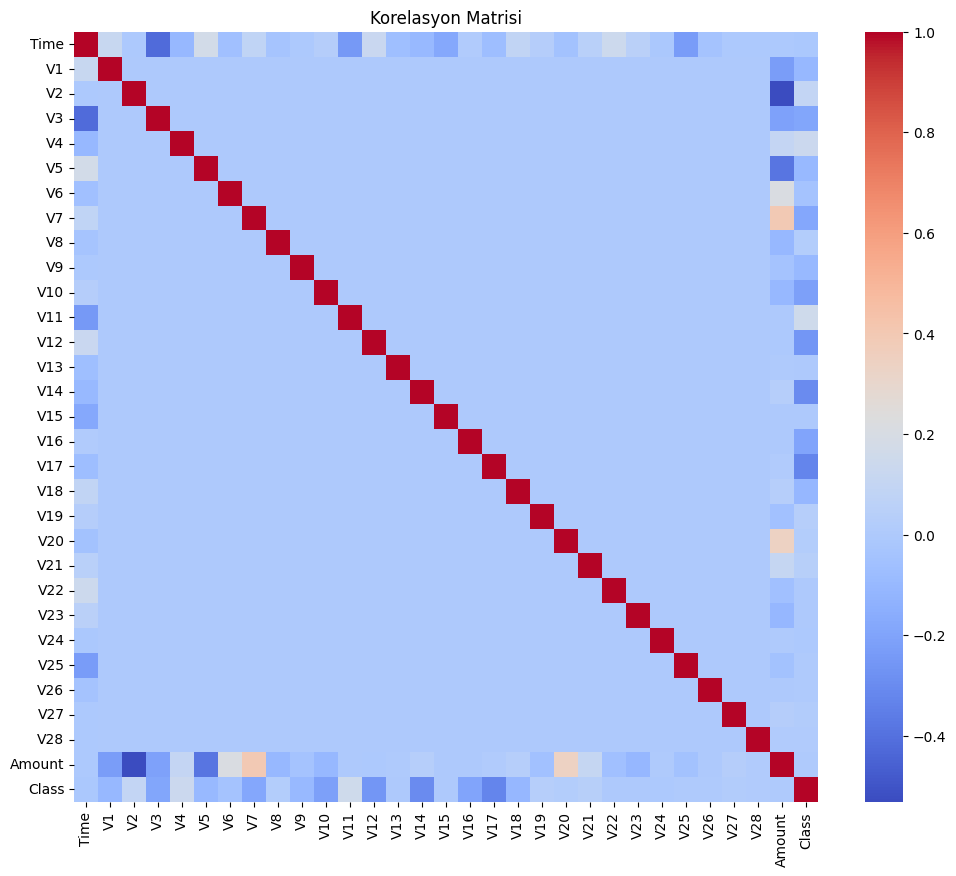

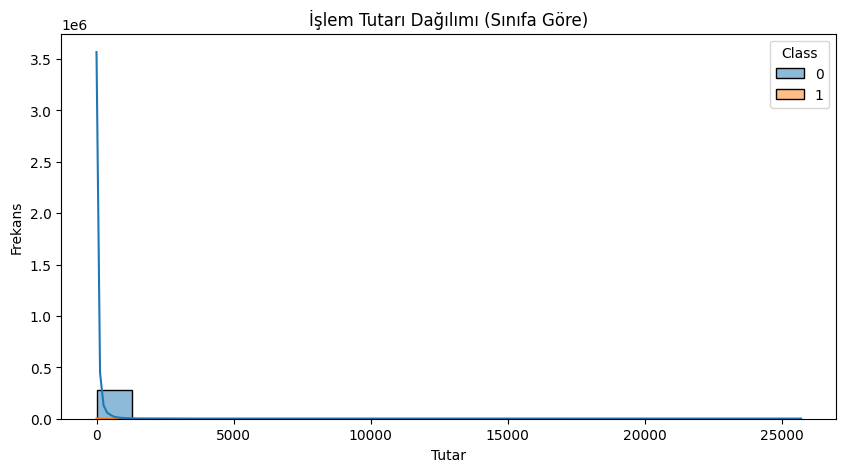

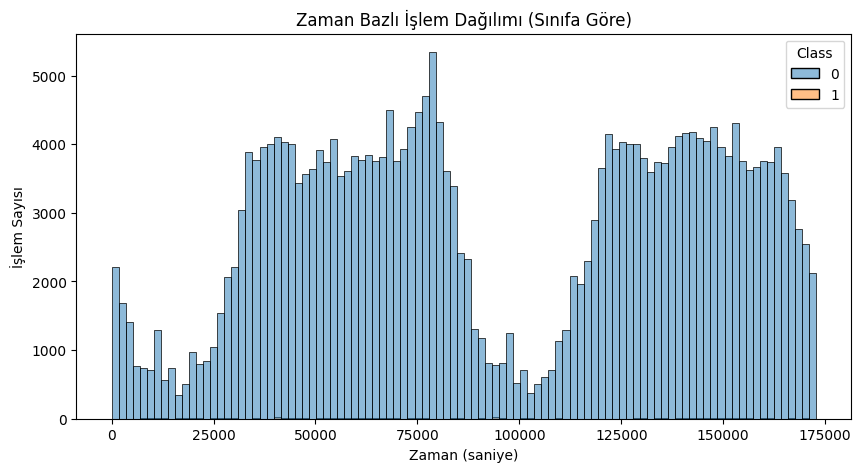

In [8]:
# Sınıf dağılımı (fraud vs normal)
print("\nSınıf Dağılımı:")
print(df['Class'].value_counts())
print("\nSınıf Dağılımı (Yüzdelik):")
print(df['Class'].value_counts(normalize=True))

# Sınıf dağılımı grafiği
plt.figure(figsize=(6,4))
sns.countplot(x='Class', data=df)
plt.title("Sınıf Dağılımı (0 = Normal, 1 = Fraud)")
plt.xlabel("Sınıf")
plt.ylabel("Adet")
plt.show()

# Korelasyon matrisi
plt.figure(figsize=(12,10))
corr = df.corr()
sns.heatmap(corr, cmap='coolwarm', annot=False)
plt.title("Korelasyon Matrisi")
plt.show()

# İşlem tutarı dağılımı (sınıflara göre)
plt.figure(figsize=(10,5))
sns.histplot(data=df, x='Amount', hue='Class', bins=20, kde=True)
plt.title("İşlem Tutarı Dağılımı (Sınıfa Göre)")
plt.xlabel("Tutar")
plt.ylabel("Frekans")
plt.show()

# Zaman bazlı işlem dağılımı
plt.figure(figsize=(10,5))
sns.histplot(data=df, x='Time', hue='Class', bins=100, kde=False)
plt.title("Zaman Bazlı İşlem Dağılımı (Sınıfa Göre)")
plt.xlabel("Zaman (saniye)")
plt.ylabel("İşlem Sayısı")
plt.show()

## PCA Dönüşümü ve Veri Hazırlama

In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Veri setini tekrar yükle
df_v1 = pd.read_csv('../data/creditcard.csv')

# 'Time' sütununu çıkar (modelleme için gerekli değil)
df_v2 = df_v1.drop(columns=['Time'])

# 'Amount' sütununu normalize et
scaler_amount = StandardScaler()
df_v2['Amount'] = scaler_amount.fit_transform(df_v2[['Amount']])

# --- V1-V28 sütunlarına PCA uygula ---
# Adım 1: V1-V28 sütunlarını normalize et
v_columns = [f'V{i}' for i in range(1, 29)]
scaler_v = StandardScaler()
v_scaled = scaler_v.fit_transform(df_v2[v_columns])

# Adım 2: Normalize edilmiş V1-V28'e PCA uygula
pca = PCA(n_components=28)
v_pca = pca.fit_transform(v_scaled)

# Adım 3: PCA çıktısından yeni DataFrame oluştur
v_pca_df = pd.DataFrame(v_pca, columns=[f'PC{i+1}' for i in range(28)])

# Adım 4: 'Amount' ve 'Class' ile birleştir
df_v2_pca = pd.concat([v_pca_df, df_v2[['Amount', 'Class']].reset_index(drop=True)], axis=1)

# Sonuçları yazdır
print("V1-V28'e PCA uygulandı.")
print("Son DataFrame boyutu:", df_v2_pca.shape)
print("Son sütunlar:", df_v2_pca.columns.tolist())

# Özellikler ve etiketlere ayır
X = df_v2_pca.drop(columns=['Class'])
y = df_v2_pca['Class']

print("\nÖzellik matrisi boyutu:", X.shape)
print("Hedef değişken boyutu:", y.shape)

V1-V28'e PCA uygulandı.
Son DataFrame boyutu: (284807, 30)
Son sütunlar: ['PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6', 'PC7', 'PC8', 'PC9', 'PC10', 'PC11', 'PC12', 'PC13', 'PC14', 'PC15', 'PC16', 'PC17', 'PC18', 'PC19', 'PC20', 'PC21', 'PC22', 'PC23', 'PC24', 'PC25', 'PC26', 'PC27', 'PC28', 'Amount', 'Class']

Özellik matrisi boyutu: (284807, 29)
Hedef değişken boyutu: (284807,)


## İşlenmiş Veriyi Kaydet

In [11]:
# İşlenmiş veriyi CSV olarak kaydet
df_v2_pca.to_csv("../data/credit_card_PCA.csv", index=False)
print("✓ İşlenmiş veri 'credit_card_PCA.csv' olarak kaydedildi.")

✓ İşlenmiş veri 'credit_card_PCA.csv' olarak kaydedildi.
